### Part 1 - Variants of Gradient Descent

Batch Gradient Descent computes gradients using **all** $n$ samples, which has major limitations for large datasets:

**Problems:**
- Each iteration processes all data (memory intensive)
- Only 1 parameter update per epoch (slow learning)
- Cannot handle streaming data

**Solution:** Update parameters more frequently using smaller data subsets. This is where
- **Stochastic Gradient Descent (SGD)** and
- **Mini-batch Gradient Descent** enable practical large-scale machine learning.

**The Limitations of Batch Gradient Descent**: Training on 100 million samples with batch gradient descent creates severe bottlenecks: each iteration takes minutes, memory maxes out, and progress is painfully slow. Let's understand why and explore better alternatives.

**Memory and Computational Costs**: Batch gradient descent loads **all** training data into memory. With 100M samples, that's ~4TB—impossible for most systems. Processing all samples per iteration means waiting seconds or minutes for each parameter update.

**Slow Updates in Practice**: Batch gradient descent updates parameters only **once per epoch**. With 1M samples and 100 iterations: only **100 updates**. Processing samples individually gives **1M updates**—10,000× more learning opportunities. Additionally, it cannot handle streaming data (spam filters, recommendation systems).



**Slow Updates in Practice**: Batch gradient descent updates parameters only **once per epoch**. With 1M samples and 100 iterations: only **100 updates**. Processing samples individually gives **1M updates**—10,000× more learning opportunities. Additionally, it cannot handle streaming data (spam filters, recommendation systems).



#### The Need for Alternatives

- **Key insight:** We don't need perfect information to make progress. Quick steps with noisy gradients often beat slow steps with exact gradients.

- **Trade-off:** Batch GD waits for perfect information (slow but precise) vs. Stochastic/Mini-batch GD uses imperfect information (fast and good enough). In practice, "good enough" delivered 1000× faster wins.

### Part 2 - Stochastic Gradient Descent (SGD)

#### The Core Idea

Stochastic Gradient Descent (SGD) uses **one random sample** at a time instead of all samples.

**Algorithm:**
```
For each epoch:
    Shuffle training data
    For each sample (xi, yi):
        1. Compute gradient: ∇Li(β)
        2. Update: β = β - α ∇Li(β)
```

**Key insight:** Frequent noisy updates often outperform infrequent perfect updates. With 1M samples: SGD makes 1M updates per epoch vs 1 update for batch GD.

**Advantages:**
- Memory efficient (one sample at a time)
- Fast updates (1M samples → 1M updates/epoch)
- Handles streaming data
- Can escape local minima due to noise
- Computational efficiency: $O(m)$ per update

**Challenges:**
- Noisy convergence (oscillates around optimum)
- Requires learning rate decay
- Cannot exploit vectorization (no matrix operations)
- More sensitive to feature scaling

#### Visualizing SGD Convergence

Let's visualize how SGD's noisy updates compare to the smooth convergence of batch GD:

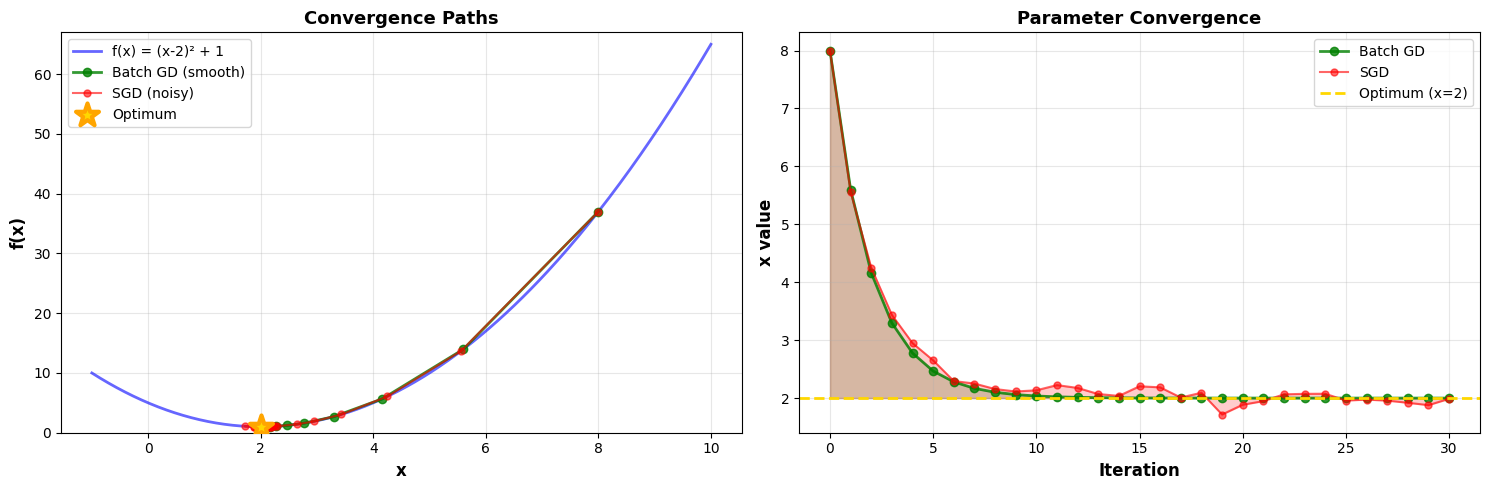

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Simple 1D function: f(x) = (x - 2)^2 + 1
def f(x):
    return (x - 2)**2 + 1

def gradient_f(x):
    return 2 * (x - 2)

# Batch Gradient Descent (smooth)
def batch_gd(x_start, alpha, iterations):
    x = x_start
    path = [x] # viz
    for _ in range(iterations):
        grad = gradient_f(x)
        x = x - alpha * grad
        path.append(x)
    return path

    # x: Current parameter value
    # alpha: Learning rate
    # grad: Current slope
    # iterations: How many times we update the parameter

# Stochastic Gradient Descent (noisy)
def stochastic_gd(x_start, alpha, iterations, noise_level=0.5):
    x = x_start
    path = [x]
    for _ in range(iterations):
        grad = gradient_f(x) + np.random.normal(0, noise_level)  # Add noise
        x = x - alpha * grad
        path.append(x)
    return path

# This SGD implementation is a simulation, not true Stochastic Gradient Descent.
# The actual difference is about how much training data we use to calculate the gradient.

# Run both methods
x_start = 8
alpha = 0.2
iterations = 30

bgd_path = batch_gd(x_start, alpha, iterations)
sgd_path = stochastic_gd(x_start, alpha, iterations)

# Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Paths on the function
x_range = np.linspace(-1, 10, 300)
y_range = f(x_range)

ax1.plot(x_range, y_range,
		 'b-',
		 linewidth=2,
		 alpha=0.6,
		 label='f(x) = (x-2)² + 1')
ax1.plot(bgd_path, [f(x) for x in bgd_path], 'go-', linewidth=2,
         markersize=6, alpha=0.8, label='Batch GD (smooth)')
ax1.plot(sgd_path, [f(x) for x in sgd_path], 'ro-', linewidth=1.5,
         markersize=5, alpha=0.6, label='SGD (noisy)')
ax1.scatter([2], [1], s=300, marker='*', color='gold',
           edgecolors='orange', linewidths=3, zorder=5, label='Optimum')
ax1.set_xlabel('x', fontsize=12, fontweight='bold')
ax1.set_ylabel('f(x)', fontsize=12, fontweight='bold')
ax1.set_title('Convergence Paths', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, max(y_range) + 2)

# Plot 2: Parameter values over iterations
ax2.plot(range(len(bgd_path)), bgd_path, 'go-', linewidth=2,
         markersize=6, alpha=0.8, label='Batch GD')
ax2.plot(range(len(sgd_path)), sgd_path, 'ro-', linewidth=1.5,
         markersize=5, alpha=0.6, label='SGD')
ax2.axhline(y=2, color='gold', linestyle='--', linewidth=2, label='Optimum (x=2)')
ax2.fill_between(range(len(bgd_path)), bgd_path, 2, alpha=0.2, color='green')
ax2.fill_between(range(len(sgd_path)), sgd_path, 2, alpha=0.2, color='red')
ax2.set_xlabel('Iteration', fontsize=12, fontweight='bold')
ax2.set_ylabel('x value', fontsize=12, fontweight='bold')
ax2.set_title('Parameter Convergence', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Part 3 - Mini-batch Gradient Descent

**The Best of Both Worlds**

Mini-batch Gradient Descent uses **small batches** of samples (e.g., 32, 64, 128) instead of all samples or just one.

**Algorithm:**
```
For each epoch:
    Shuffle training data
    Divide into mini-batches of size B
    For each mini-batch:
        1. Compute gradient using batch: ∇L_batch(β)
        2. Update: β = β - α ∇L_batch(β)
```

**The sweet spot:** Not too big (like batch GD), not too small (like SGD)—just right. Gradients from 32 samples are much more reliable than from 1, while still updating much faster than using all samples.

**Choosing Batch Size**

- **Common choices:**
	- **Small (16-64)**: More updates, more noise, better generalization
	- **Medium (128-256)**: Good balance—most common in practice
	- **Large (512+)**: Smoother convergence, better GPU utilization

- **Guidelines:**
	- Use powers of 2 (GPU optimization)
	- Small dataset (< 10K) → 32-64
	- Medium dataset (10K-1M) → 128-256  
	- Large dataset (> 1M) → 256-512
	- **Sweet spot**: Usually 32-256

**Advantages**

Mini-batch GD combines the best of both:

**Efficiency:**
- Faster than batch GD, more stable than SGD
- Vectorized operations (optimal GPU/CPU utilization)
- Memory efficient (loads one batch at a time)

**Convergence:**
- More stable than SGD (averaged gradient)
- Faster than batch GD (frequent updates)
- Natural regularization from sampling

**Why it's the industry standard:** Used in deep learning, large-scale ML, and production systems. Pure batch GD and pure SGD are rarely used in modern applications.

<img src="https://media.geeksforgeeks.org/wp-content/uploads/20250609112950096667/Different-Variants-of-Gradient-Descent.webp">

### Part 4 - Implementing All Three Variants

In [2]:
#Data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Generate house price data
np.random.seed(42)
n = 100

house_size = 800 + np.random.rand(n) * 2200
house_age = np.random.randint(0, 31, n)
distance_to_city = 1 + np.random.rand(n) * 19

house_price = (50_000 +
               150 * house_size -
               2_000 * house_age -
               8_000 * distance_to_city +
               np.random.normal(0, 20_000, n))

# Prepare data
X = np.column_stack([house_size, house_age, distance_to_city])
y = house_price

# Feature scaling (critical for gradient descent!)
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X_scaled = (X - X_mean) / X_std

print("=" * 70)
print("HOUSE PRICE DATASET")
print("=" * 70)
print(f"Samples: {n}")
print(f"Features: {X.shape[1]}")
print(f"\nFeature scaling applied:")
print(f"  Before: Size ranges from {X[:,0].min():.0f} to {X[:,0].max():.0f}")
print(f"  After:  Size ranges from {X_scaled[:,0].min():.2f} to {X_scaled[:,0].max():.2f}")


HOUSE PRICE DATASET
Samples: 100
Features: 3

Feature scaling applied:
  Before: Size ranges from 812 to 2971
  After:  Size ranges from -1.57 to 1.75


#### Model

Now let's implement all three variants and compare their behavior:

In [3]:
class LinearRegressionGD:
    """Linear Regression with mini-batch gradient descent.

    Note: batch_size controls the variant:
    - batch_size = 1: Stochastic GD
    - batch_size = n_samples: Batch GD
    - batch_size = b (1 < b < n): Mini-batch GD
    """

    def __init__(self, learning_rate=0.01, n_iterations=100, batch_size=32):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.batch_size = batch_size
        self.coefficients = None
        self.intercept = None
        self.loss_history = []

    def fit(self, X, y):
        """Fit the model using mini-batch gradient descent."""
        n_samples, n_features = X.shape

        # Add intercept column
        X_with_intercept = np.column_stack([np.ones(n_samples), X])

        # Initialize parameters
        beta = np.zeros(n_features + 1)

        # Training loop
        for iteration in range(self.n_iterations):
            # Shuffle data each epoch
            indices = np.random.permutation(n_samples)
            epoch_losses = []

            # Process data in mini-batches
            for start_idx in range(0, n_samples, self.batch_size):
                end_idx = min(start_idx + self.batch_size, n_samples)
                batch_indices = indices[start_idx:end_idx]

                X_batch = X_with_intercept[batch_indices]
                y_batch = y[batch_indices]

                # Compute predictions and gradients
                y_pred = X_batch @ beta
                residuals = y_pred - y_batch
                gradient = (2/len(batch_indices)) * X_batch.T @ residuals

                # Update parameters
                beta = beta - self.learning_rate * gradient

                # Track loss for this batch
                epoch_losses.append(np.mean(residuals ** 2))

            # Average loss for the epoch
            self.loss_history.append(np.mean(epoch_losses))

        # Store final parameters
        self.intercept = beta[0]
        self.coefficients = beta[1:]

        return self

    def predict(self, X):
        """Make predictions."""
        return self.intercept + X @ self.coefficients

    def evaluate(self, X, y):
        """Calculate MSE loss on the entire dataset."""
        y_pred = self.predict(X)
        mse = np.mean((y_pred - y) ** 2)
        return mse

In [4]:
# Train Batch Gradient Descent
print("=" * 70)
print("🔄 TRAINING BATCH GRADIENT DESCENT")
print("=" * 70)

# Hyperparameters for Batch GD
batch_learning_rate = 0.1
batch_n_iterations = 50
batch_size = X_scaled.shape[0]  # All samples

print(f"📊 Hyperparameters:")
print(f"   • Learning rate: {batch_learning_rate}")
print(f"   • Iterations: {batch_n_iterations}")
print(f"   • Batch size: {batch_size} (all samples)")

model_batch = LinearRegressionGD(learning_rate=batch_learning_rate,
								 n_iterations=batch_n_iterations,
								 batch_size=batch_size)

model_batch.fit(X_scaled, y)

# Evaluate on full dataset
final_loss_batch = model_batch.evaluate(X_scaled, y)

print(f"\n✅ Results:")
print(f"   • Initial loss: {model_batch.loss_history[0]:,.2f}")
print(f"   • Final loss (full dataset): {final_loss_batch:,.2f}")
print("=" * 70)

🔄 TRAINING BATCH GRADIENT DESCENT
📊 Hyperparameters:
   • Learning rate: 0.1
   • Iterations: 50
   • Batch size: 100 (all samples)

✅ Results:
   • Initial loss: 52,056,602,191.49
   • Final loss (full dataset): 349,702,995.84


In [5]:
# Train Stochastic Gradient Descent
print("=" * 70)
print("🔄 TRAINING STOCHASTIC GRADIENT DESCENT")
print("=" * 70)

# Hyperparameters for Stochastic GD
stochastic_learning_rate = 0.01
stochastic_n_iterations = 200
stochastic_batch_size = 1  # One sample at a time

print(f"📊 Hyperparameters:")
print(f"   • Learning rate: {stochastic_learning_rate}")
print(f"   • Iterations: {stochastic_n_iterations}")
print(f"   • Batch size: {stochastic_batch_size} (one sample)")

model_stochastic = LinearRegressionGD(learning_rate=stochastic_learning_rate,
									  n_iterations=stochastic_n_iterations,
									  batch_size=stochastic_batch_size)

model_stochastic.fit(X_scaled, y)

# Evaluate on full dataset
final_loss_stochastic = model_stochastic.evaluate(X_scaled, y)

print(f"\n✅ Results:")
print(f"   • Initial loss (batch): {model_stochastic.loss_history[0]:,.2f}")
print(f"   • Final loss (full dataset): {final_loss_stochastic:,.2f}")
print("=" * 70)

🔄 TRAINING STOCHASTIC GRADIENT DESCENT
📊 Hyperparameters:
   • Learning rate: 0.01
   • Iterations: 200
   • Batch size: 1 (one sample)

✅ Results:
   • Initial loss (batch): 13,796,527,225.05
   • Final loss (full dataset): 354,524,960.48


In [6]:
# Train Mini-batch Gradient Descent
print("=" * 70)
print("🔄 TRAINING MINI-BATCH GRADIENT DESCENT")
print("=" * 70)

# Hyperparameters for Mini-batch GD
minibatch_learning_rate = 0.01
minibatch_n_iterations = 100
minibatch_batch_size = 32  # Mini-batches of 32

print(f"📊 Hyperparameters:")
print(f"   • Learning rate: {minibatch_learning_rate}")
print(f"   • Iterations: {minibatch_n_iterations}")
print(f"   • Batch size: {minibatch_batch_size}")

model_minibatch = LinearRegressionGD(learning_rate=minibatch_learning_rate,
									 n_iterations=minibatch_n_iterations,
									 batch_size=minibatch_batch_size)

model_minibatch.fit(X_scaled, y)

# Evaluate on full dataset
final_loss_minibatch = model_minibatch.evaluate(X_scaled, y)

print(f"\n✅ Results:")
print(f"   • Initial loss (batch): {model_minibatch.loss_history[0]:,.2f}")
print(f"   • Final loss (full dataset): {final_loss_minibatch:,.2f}")
print("=" * 70)

🔄 TRAINING MINI-BATCH GRADIENT DESCENT
📊 Hyperparameters:
   • Learning rate: 0.01
   • Iterations: 100
   • Batch size: 32

✅ Results:
   • Initial loss (batch): 49,167,298,205.05
   • Final loss (full dataset): 350,285,198.63


In [7]:
# Collect models for comparison
models = {
    'batch': model_batch,
    'stochastic': model_stochastic,
    'minibatch': model_minibatch
}

print("\n" + "=" * 70)
print("✅ ALL MODELS TRAINED SUCCESSFULLY!")
print("=" * 70)
print("\n📊 Summary (Loss evaluated on full dataset):")
print(f"   • Batch GD:      Final loss = {final_loss_batch:,.2f}")
print(f"   • Stochastic GD: Final loss = {final_loss_stochastic:,.2f}")
print(f"   • Mini-batch GD: Final loss = {final_loss_minibatch:,.2f}")
print("=" * 70)


✅ ALL MODELS TRAINED SUCCESSFULLY!

📊 Summary (Loss evaluated on full dataset):
   • Batch GD:      Final loss = 349,702,995.84
   • Stochastic GD: Final loss = 354,524,960.48
   • Mini-batch GD: Final loss = 350,285,198.63


### Part 5 - When to Use Each Variant

**Comparison:**

| Aspect | Batch GD | Stochastic GD | Mini-batch GD |
|--------|----------|---------------|---------------|
| **Gradient** | All $n$ samples | 1 sample | $B$ samples |
| **Updates/epoch** | 1 | $n$ | $\frac{n}{B}$ |
| **Memory** | $O(n)$ | $O(1)$ | $O(B)$ |
| **Convergence** | Smooth | Very noisy | Moderate |
| **Speed** | Slow | Fast | Very fast |
| **Best for** | Small data | Online learning | Most cases |

**Quick Guide:**

**Batch GD:** Small datasets (< 10K), smooth convergence needed. Rarely used in modern ML.

**Stochastic GD:** Online learning, streaming data, very large datasets. Not common (mini-batch is usually better).

**Mini-batch GD:** Medium-large datasets (10K+), deep learning, GPU acceleration. **Default choice in 95% of cases.**

**Modern Best Practices:**
- Default: Mini-batch with B=32-256
- Learning rate: 0.001-0.01 with schedules
- Batch sizes: multiples of 32 for GPU efficiency